# Passo 1: Análise Exploratória no Domínio do Tempo

## 1.1. Validação Física dos Eixos e Efeito da Gravidade (Janela de 1 Segundo)
O sensor MPU6050 coleta 1000 amostras por segundo (1 kHz) nos eixos X, Y e Z. Antes de analisar as vibrações do motor, visualizamos 1 segundo de dados brutos (1000 linhas) em um único plano para identificar a orientação física do sensor colado na carcaça:
* **Eixos X e Y:** Oscilam próximos a `0`, indicando que estão perpendiculares à força da gravidade.
* **Eixo Z:** Permanece deslocado próximo a `10.8` (~9,8 m/s² somado ao offset natural do componente), provando que este eixo está alinhado verticalmente com a gravidade.

In [93]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [94]:
df_1khz = pd.read_csv('C:\\Users\\santo\\OneDrive\\Área de Trabalho\\TCC\\DADOS\\DADOS_NORMAIS_1KHZ\\dados_valores_xyz_puro.csv')

In [95]:
df_1khz.head()

,x,y,z
0,-0.749385,-0.356736,10.81940
1,-0.749385,0.426168,10.97742
2,0.380678,1.041478,11.21205
3,0.246603,1.108515,10.96544
4,0.411803,0.632069,10.79546


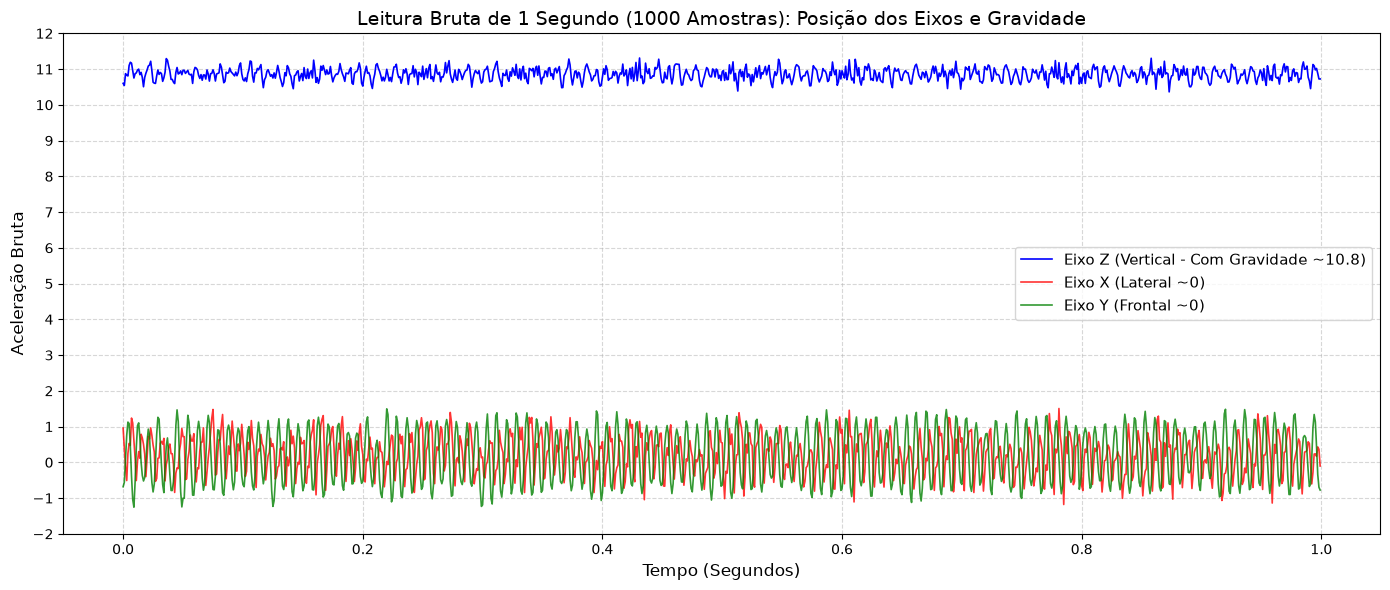

In [96]:
# 1. Selecionando 1 segundo (1000 amostras) em um trecho estável do teste
amostra_1s = df_1khz.iloc[100000 : 101000].copy()

# Criando o eixo de tempo de 0 a 1 segundo (1000 pontos)
tempo_1s = np.linspace(0, 1, 1000, endpoint=False)

# 2. Plotando os 3 eixos juntos para comparar a posição da Gravidade
plt.figure(figsize=(14, 6))

plt.plot(tempo_1s, amostra_1s['z'], color='blue', label='Eixo Z (Vertical - Com Gravidade ~10.8)', linewidth=1.2)
plt.plot(tempo_1s, amostra_1s['x'], color='red', label='Eixo X (Lateral ~0)', alpha=0.8, linewidth=1.2)
plt.plot(tempo_1s, amostra_1s['y'], color='green', label='Eixo Y (Frontal ~0)', alpha=0.8, linewidth=1.2)

plt.title('Leitura Bruta de 1 Segundo (1000 Amostras): Posição dos Eixos e Gravidade', fontsize=14)
plt.xlabel('Tempo (Segundos)', fontsize=12)
plt.ylabel('Aceleração Bruta', fontsize=12)
plt.yticks(np.arange(-2, 13, 1)) # Facilita ver a distância do 0 até o 11
plt.legend(loc='center right', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

## 1.2. Evolução da Energia de Vibração (Desvio Padrão Segundo a Segundo)
Para visualizar todo o experimento e identificar onde ocorrem as trocas entre as **3 velocidades**, agrupamos o dataset em blocos de 1 segundo (1000 amostras por bloco) e calculamos o **Desvio Padrão (`std`)** de cada segundo.

O Desvio Padrão remove automaticamente o efeito estático da gravidade (10.8 no Eixo Z) e mede apenas a dispersão (intensidade da trepidação) em torno do ponto central. Os "degraus" no gráfico revelam os instantes exatos de mudança de velocidade.

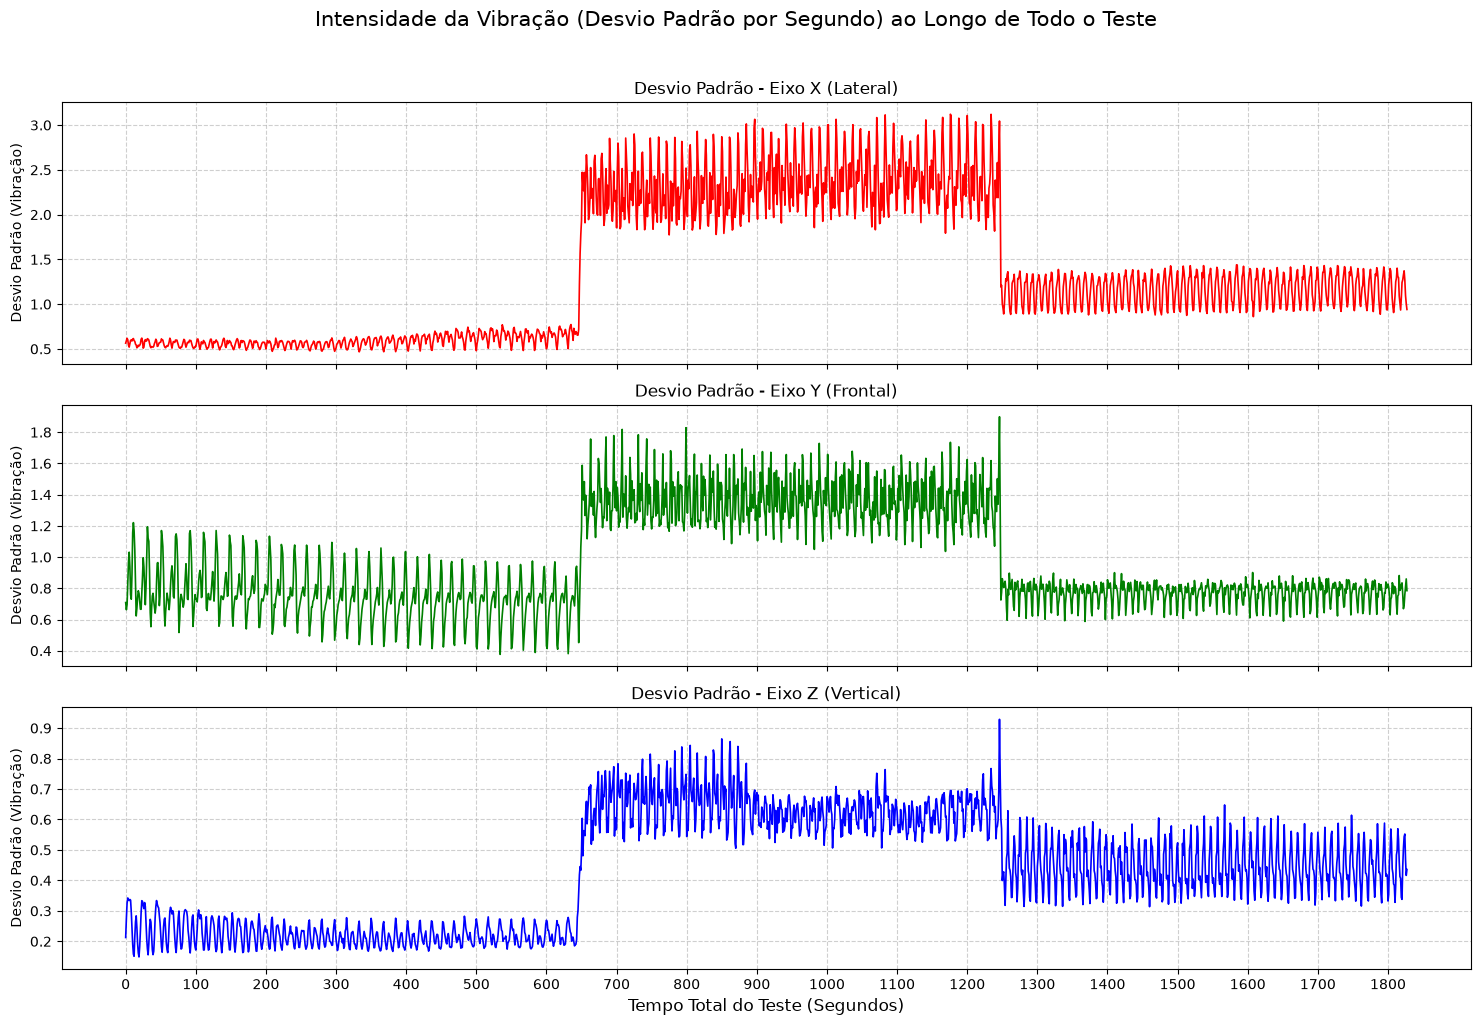

In [97]:
# 1. Criando um identificador para cada segundo do teste (cada 1000 linhas = 1 segundo)
tamanho_janela = 1000
df_1khz['segundo'] = np.arange(len(df_1khz)) // tamanho_janela

# 2. Calculando o Desvio Padrão de X, Y e Z para cada segundo
std_por_segundo = df_1khz.groupby('segundo')[['x', 'y', 'z']].std()

# 3. Plotando os 3 eixos separados para enxergar os degraus das 3 velocidades
fig, axs = plt.subplots(3, 1, figsize=(15, 10), sharex=True)
fig.suptitle('Intensidade da Vibração (Desvio Padrão por Segundo) ao Longo de Todo o Teste', fontsize=15, y=1.02)

eixos = ['x', 'y', 'z']
nomes = ['Eixo X (Lateral)', 'Eixo Y (Frontal)', 'Eixo Z (Vertical)']
cores = ['red', 'green', 'blue']

for i in range(3):
    axs[i].plot(std_por_segundo.index, std_por_segundo[eixos[i]], color=cores[i], linewidth=1.2)
    axs[i].set_title(f'Desvio Padrão - {nomes[i]}', fontsize=12)
    axs[i].set_ylabel('Desvio Padrão (Vibração)')
    axs[i].grid(True, linestyle='--', alpha=0.6)
    
    # Colocando marcações de 100 em 100 segundos no eixo X para facilitar achar onde cortar
    axs[i].set_xticks(np.arange(0, len(std_por_segundo) + 1, 100))

axs[2].set_xlabel('Tempo Total do Teste (Segundos)', fontsize=12)
plt.tight_layout()
plt.show()

## 1.3. Segmentação do Dataset nas 3 Velocidades Operacionais
A partir da inspeção visual dos degraus no gráfico de Desvio Padrão, identificamos os momentos de transição de velocidade. 

Para garantir que as análises futuras (e o modelo de Machine Learning) utilizem apenas dados de regime permanente (velocidade estabilizada), separamos o dataset em **3 DataFrames independentes**, descartando uma margem de segurança durante o acionamento manual dos botões.

In [98]:
# 1. Definindo os intervalos de tempo (em Segundos) com margem de segurança
# (Ajuste estes números caso o gráfico da Etapa 1.2 mostre o degrau em outro segundo)
inicio_v1, fim_v1 = 20, 620      # Velocidade 1 (Descarta os primeiros 20s e para antes da troca dos ~640s)
inicio_v2, fim_v2 = 660, 1230    # Velocidade 2 (Começa após estabilizar nos 660s e para antes dos ~1250s)
inicio_v3, fim_v3 = 1270, 1780   # Velocidade 3 (Começa aos 1270s e vai até quase o fim do teste)

# 2. Separando em 3 DataFrames usando a coluna 'segundo' que criamos
df_vel1 = df_1khz[(df_1khz['segundo'] >= inicio_v1) & (df_1khz['segundo'] < fim_v1)].copy()
df_vel2 = df_1khz[(df_1khz['segundo'] >= inicio_v2) & (df_1khz['segundo'] < fim_v2)].copy()
df_vel3 = df_1khz[(df_1khz['segundo'] >= inicio_v3) & (df_1khz['segundo'] < fim_v3)].copy()

# 3. Criando uma tabela resumo para validar a separação e comparar o Desvio Padrão
resumo_velocidades = pd.DataFrame({
    'Velocidade': ['Velocidade 1 (Baixa)', 'Velocidade 2 (Média)', 'Velocidade 3 (Alta)'],
    'Intervalo (s)': [f'{inicio_v1}s a {fim_v1}s', f'{inicio_v2}s a {fim_v2}s', f'{inicio_v3}s a {fim_v3}s'],
    'Total de Linhas': [len(df_vel1), len(df_vel2), len(df_vel3)],
    'Std Eixo X': [df_vel1['x'].std(), df_vel2['x'].std(), df_vel3['x'].std()],
    'Std Eixo Y': [df_vel1['y'].std(), df_vel2['y'].std(), df_vel3['y'].std()],
    'Std Eixo Z': [df_vel1['z'].std(), df_vel2['z'].std(), df_vel3['z'].std()]
})

display(resumo_velocidades.round(4))

,Velocidade,Intervalo (s),Total de Linhas,Std Eixo X,Std Eixo Y,Std Eixo Z
0,Velocidade 1 (Baixa),20s a 620s,600000,0.7766,0.7963,0.2268
1,Velocidade 2 (Média),660s a 1230s,570000,2.4262,1.3883,0.6424
2,Velocidade 3 (Alta),1270s a 1780s,510000,1.2704,0.7961,0.4528


## 1.4. Preparação para Visualização Multidimensional (Remoção do Componente DC)

Antes de comparar as **3 velocidades** na mesma escala ou no espaço 3D, precisamos remover o **Componente DC** (a força estática da gravidade que mantém o Eixo Z deslocado próximo a `10.8`). 

Subtraindo a média de cada eixo (`sinal - sinal.mean()`), centralizamos todas as oscilações exatamente no ponto zero `(0, 0, 0)`, isolando apenas a vibração dinâmica do ventilador.

In [99]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

def extrair_janela(df, num_segundos=1, remove_dc=True):
    """
    Recorta N segundos do DataFrame (1000 amostras por segundo)
    e remove a média (gravidade/DC) se remove_dc=True.
    """
    amostra = df[['x', 'y', 'z']].iloc[:num_segundos * 1000].copy()
    if remove_dc:
        amostra = amostra - amostra.mean()
    return amostra.values

## 1.5. Comparação Direta dos 3 Eixos por Velocidade (Janela de 1 Segundo)

Com o efeito da gravidade removido, plotamos 1 segundo (1000 amostras) de cada velocidade utilizando a **mesma escala vertical (`sharey=True`)**. Isso permite comparar visualmente a espessura da faixa de vibração entre os três estágios de operação.

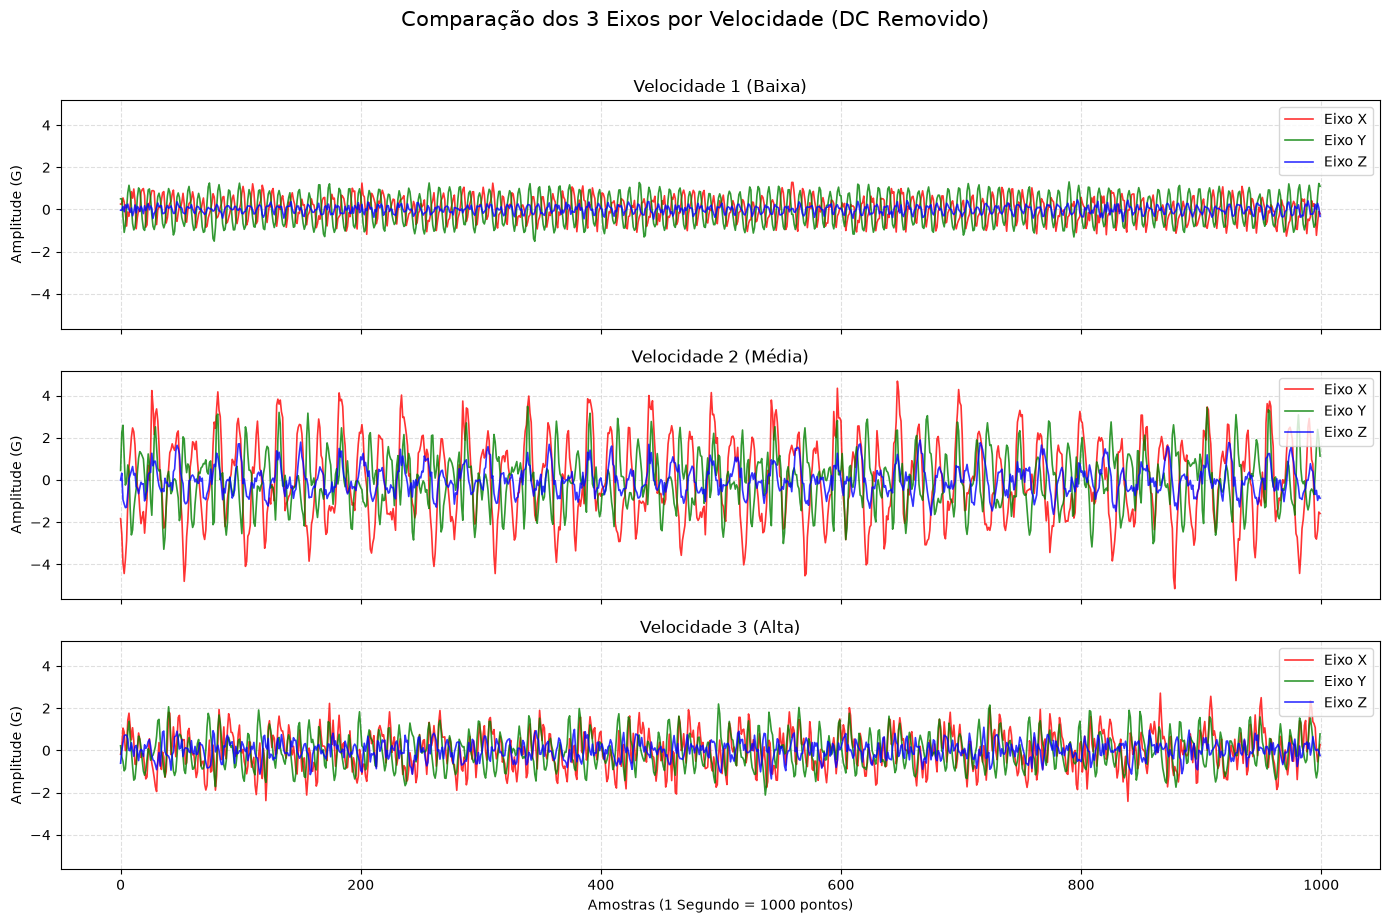

In [100]:
def plot_comparison_3vel(df_v1, df_v2, df_v3, remove_dc=True):
    dados = [
        extrair_janela(df_v1, num_segundos=1, remove_dc=remove_dc),
        extrair_janela(df_v2, num_segundos=1, remove_dc=remove_dc),
        extrair_janela(df_v3, num_segundos=1, remove_dc=remove_dc)
    ]
    titulos = [
        "Velocidade 1 (Baixa)", 
        "Velocidade 2 (Média)", 
        "Velocidade 3 (Alta)"
    ]
    
    fig, axs = plt.subplots(3, 1, figsize=(14, 9), sharex=True, sharey=True)
    fig.suptitle(
        "Comparação dos 3 Eixos por Velocidade" + (" (DC Removido)" if remove_dc else ""),
        fontsize=15, y=1.02
    )
    
    cores_eixos = ['red', 'green', 'blue']
    for idx, ax in enumerate(axs):
        for i, axis in enumerate(["X", "Y", "Z"]):
            ax.plot(dados[idx][:, i], label=f"Eixo {axis}", color=cores_eixos[i], alpha=0.8, linewidth=1.2)
        ax.set_title(titulos[idx], fontsize=12)
        ax.set_ylabel("Amplitude (G)")
        ax.legend(loc="upper right")
        ax.grid(True, linestyle="--", alpha=0.4)
        
    axs[2].set_xlabel("Amostras (1 Segundo = 1000 pontos)")
    plt.tight_layout()
    plt.show()

# Gerando o gráfico comparativo 2D
plot_comparison_3vel(df_vel1, df_vel2, df_vel3, remove_dc=True)

## 1.6. Dispersão 3D dos Dados Brutos (`raw`)

Plotamos os eixos **X, Y e Z** como coordenadas de um cubo tridimensional durante 2 segundos (2000 pontos por velocidade). Como removemos o DC, todas as nuvens de pontos partem do centro `(0, 0, 0)`, revelando o volume espacial ocupado pela trepidação de cada velocidade.

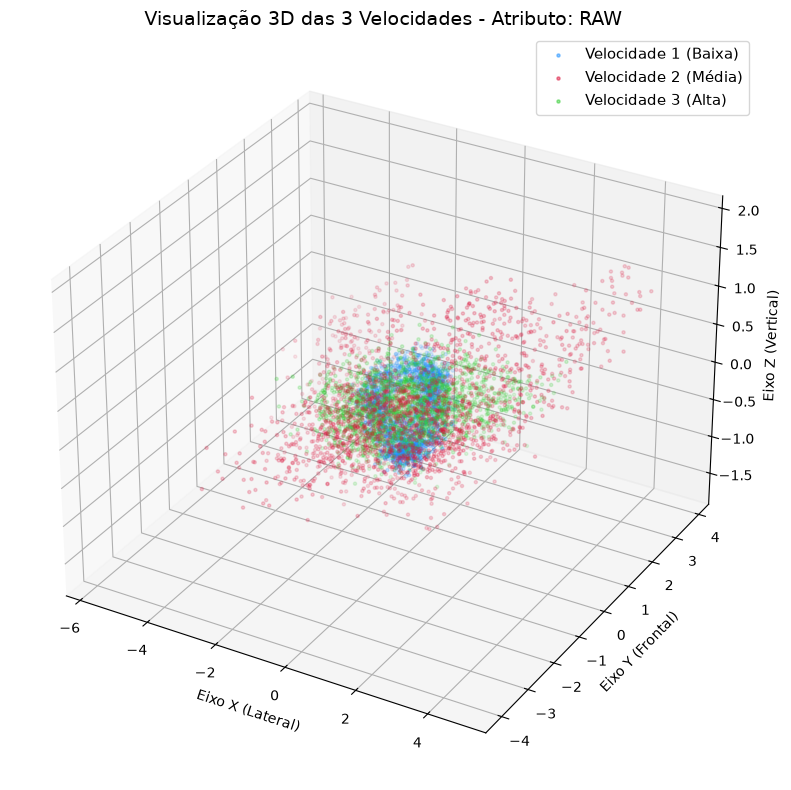

In [101]:
def plot_3d_scatter_3vel(df_v1, df_v2, df_v3, feature_type="raw", segundos_raw=2):
    """
    Plota as 3 velocidades em 3D.
    Opções para feature_type: 'raw', 'std', 'variance', 'kurtosis', 'mean'
    """
    fig = plt.figure(figsize=(9, 8))
    ax = fig.add_subplot(111, projection="3d")
    
    dfs = [df_v1, df_v2, df_v3]
    nomes = ["Velocidade 1 (Baixa)", "Velocidade 2 (Média)", "Velocidade 3 (Alta)"]
    cores = ["dodgerblue", "crimson", "limegreen"]
    
    for idx, df in enumerate(dfs):
        if feature_type == "raw":
            pontos = extrair_janela(df, num_segundos=segundos_raw, remove_dc=True)
        else:
            # Remove a gravidade (DC) antes de agrupar segundo a segundo
            df_sem_dc = df[['x', 'y', 'z']] - df[['x', 'y', 'z']].mean()
            agrupado = df_sem_dc.groupby(df['segundo'])
            
            if feature_type == "std":
                pontos = agrupado.std().values
            elif feature_type == "variance":
                pontos = agrupado.var().values
            elif feature_type == "mean":
                pontos = df.groupby('segundo')[['x', 'y', 'z']].mean().values
            elif feature_type == "kurtosis":
                pontos = agrupado.apply(
                    lambda g: pd.Series(stats.kurtosis(g, axis=0), index=['x', 'y', 'z'])
                ).values

        ax.scatter(
            pontos[:, 0], pontos[:, 1], pontos[:, 2],
            color=cores[idx], 
            alpha=0.5, 
            s=20 if feature_type != "raw" else 5, 
            label=nomes[idx]
        )

    ax.set_xlabel("Eixo X (Lateral)")
    ax.set_ylabel("Eixo Y (Frontal)")
    ax.set_zlabel("Eixo Z (Vertical)")
    ax.set_title(f"Visualização 3D das 3 Velocidades - Atributo: {feature_type.upper()}", fontsize=14)
    ax.legend(fontsize=11)
    plt.tight_layout()
    plt.show()

# Gerando o gráfico 3D com dados brutos (2 segundos de cada velocidade)
plot_3d_scatter_3vel(df_vel1, df_vel2, df_vel3, feature_type="raw", segundos_raw=2)

## 1.7. Separação de Clusters 3D por Janela de 1 Segundo (`std` e `variance`)

Em vez de plotar milhares de pontos brutos sobrepostos no centro `(0, 0, 0)`, resumimos cada **1 segundo de operação** em um único ponto estatístico (Desvio Padrão ou Variância nos eixos X, Y e Z). 

Isso transforma a nuvem embaralhada em **agrupamentos (*clusters*) distintos no espaço 3D**, demonstrando visualmente como os diferentes regimes do ventilador se separam espacialmente.

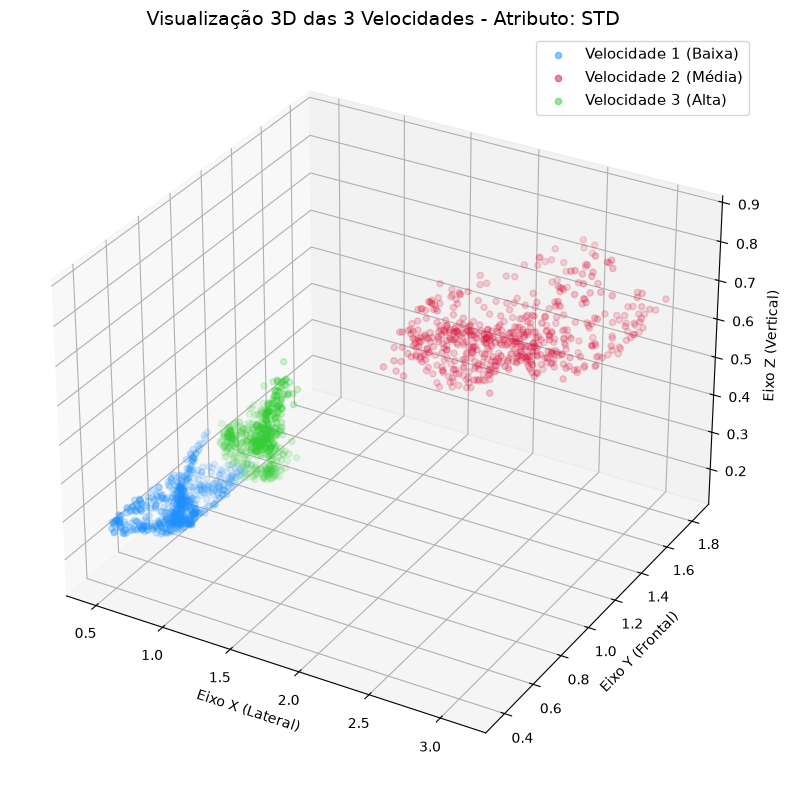

In [102]:
# Gerando o gráfico 3D para o Desvio Padrão (1 ponto = 1 segundo do teste)
plot_3d_scatter_3vel(df_vel1, df_vel2, df_vel3, feature_type="std")

# Opcional: Você pode testar também 'variance' ou 'kurtosis' descomentando abaixo:
#plot_3d_scatter_3vel(df_vel1, df_vel2, df_vel3, feature_type="variance")
#plot_3d_scatter_3vel(df_vel1, df_vel2, df_vel3, feature_type="kurtosis")

### 1.8. Análise Tridimensional dos Clusters de Vibração (STD)

O gráfico de dispersão 3D utilizando o Desvio Padrão (STD) a cada 1 segundo revelou um comportamento dinâmico riquíssimo e de grande valor para o diagnóstico preditivo:

1. **Separação Perfeita (Clusters):** A estatística de STD foi capaz de isolar as três velocidades em "ilhas" (clusters) completamente distintas no espaço 3D, o que prova que o Desvio Padrão é uma variável (*feature*) de altíssimo valor para o treinamento de modelos de Machine Learning.
2. **O Fenômeno dos "Pulinhos" (Ressonância na Velocidade 2):** 
   Fisicamente, a Velocidade 2 (Média - em Vermelho) apresenta o comportamento mais severo do sistema. Ela não apenas se desloca drasticamente nos eixos de cisalhamento horizontal (X e Y), mas também **decola no Eixo Z (Vertical)**, atingindo picos de desvio padrão próximos a `0.9` (enquanto a Velocidade 3 se estabiliza abaixo de `0.6` e a Velocidade 1 abaixo de `0.35`). 
   Isso comprova que a Velocidade 2 excita a frequência natural da estrutura, fazendo o ventilador vibrar violentamente na vertical (o equivalente a "dar pulinhos" ou saltos de aceleração no plano vertical) devido ao efeito de ressonância mecânica. Ao acelerar para a Velocidade 3 (Alta - em Verde), o sistema supera essa zona crítica e se autoestabiliza, reduzindo a severidade vibratória global.

---

# Passo 2: Entendendo a Transformada de Fourier (FFT) Passo a Passo

## 2.1. Recorte de 5 Segundos e Centralização no Zero (Remoção da Gravidade)
Antes de aplicar a FFT, isolamos **5 segundos (5000 amostras)** de cada velocidade. 
Em seguida, subtraímos a média de cada eixo (`sinal - sinal.mean()`). Essa operação **não altera nenhuma frequência de vibração** (não reduz os 120 Hz nem o giro do motor); ela serve apenas para zerar a força constante da gravidade (0 Hz), trazendo os três eixos para o centro `0`.

In [89]:
import numpy as np
import matplotlib.pyplot as plt

# Definindo o tamanho do recorte: 5 segundos = 5000 linhas (a 1000 Hz)
taxa_amostragem = 1000
segundos = 5
N = segundos * taxa_amostragem

# 1. Recortando 5 segundos de cada velocidade
recorte_v1 = df_vel1.iloc[:N].copy()
recorte_v2 = df_vel2.iloc[:N].copy()
recorte_v3 = df_vel3.iloc[:N].copy()

# 2. Subtraindo a média (Centralizando em 0 para remover a gravidade estática de 0 Hz)
for recorte in [recorte_v1, recorte_v2, recorte_v3]:
    recorte['x_zero'] = recorte['x'] - recorte['x'].mean()
    recorte['y_zero'] = recorte['y'] - recorte['y'].mean()
    recorte['z_zero'] = recorte['z'] - recorte['z'].mean()

print(f"Recortes criados com sucesso! Total de pontos por recorte (N): {N}")
print("Média do Eixo Z na Vel 1 ANTES:", round(recorte_v1['z'].mean(), 4))
print("Média do Eixo Z na Vel 1 DEPOIS:", round(recorte_v1['z_zero'].mean(), 4))
print("Média do Eixo X na Vel 2 ANTES:", round(recorte_v2['x'].mean(), 4))
print("Média do Eixo X na Vel 2 DEPOIS:", round(recorte_v2['x_zero'].mean(), 4))
print("Média do Eixo Y na Vel 3 ANTES:", round(recorte_v3['y'].mean(), 4))
print("Média do Eixo Y na Vel 3 DEPOIS:", round(recorte_v3['y_zero'].mean(), 4))

Recortes criados com sucesso! Total de pontos por recorte (N): 5000
Média do Eixo Z na Vel 1 ANTES: 10.8059
Média do Eixo Z na Vel 1 DEPOIS: -0.0
Média do Eixo X na Vel 2 ANTES: -0.2439
Média do Eixo X na Vel 2 DEPOIS: 0.0
Média do Eixo Y na Vel 3 ANTES: -0.2344
Média do Eixo Y na Vel 3 DEPOIS: -0.0


## 2.2. Aplicando a FFT Crucial na Velocidade 1 (Baixa)
Transformamos os 5000 pontos de tempo da **Velocidade 1** em frequências (Hertz):
* `np.fft.rfftfreq(N, d=1/1000)`: Cria a régua horizontal de `0 Hz` até `500 Hz` (de 0.2 em 0.2 Hz).
* `np.abs(np.fft.rfft(...)) * (2.0 / N)`: Calcula a força (Magnitude em G) de cada frequência.

Na **Velocidade 1**, como a hélice gira devagar (~11.2 Hz) e gera pouca vibração mecânica, o gráfico é dominado pelo ruído eletromagnético do motor em **120 Hz** e **240 Hz**.

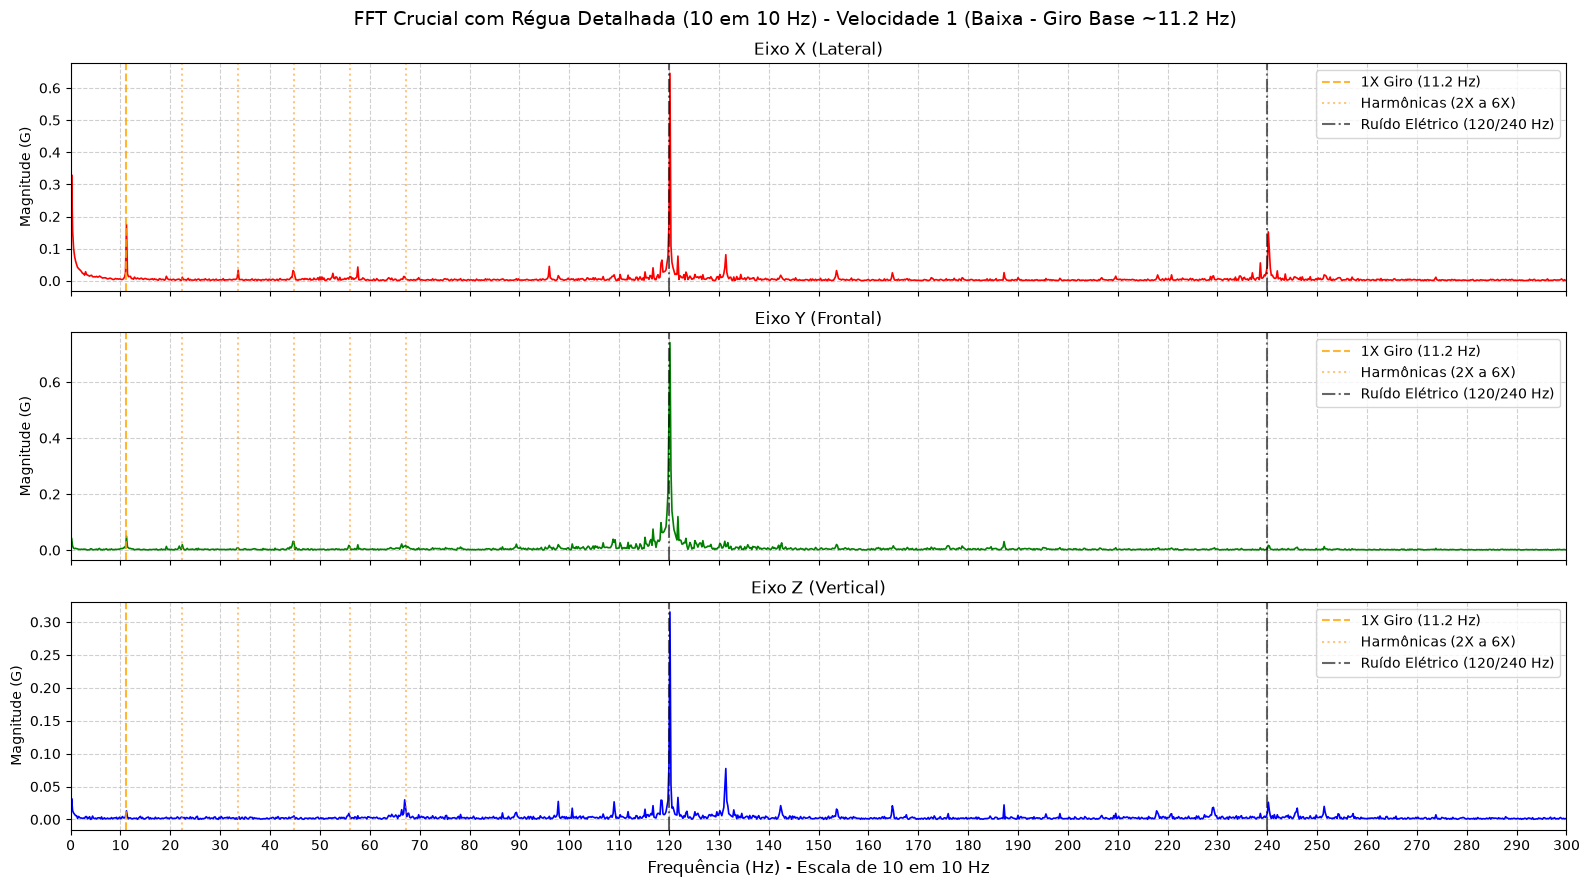

In [ ]:
# =====================================================================
# 1. DEFININDO OS PARÂMETROS E A RÉGUA DE FREQUÊNCIAS
# =====================================================================
taxa_amostragem = 1000  # 1000 Hz
segundos = 5
N = segundos * taxa_amostragem  # 5000 amostras

# Régua horizontal de frequências (de 0 a 500 Hz, pulando de 0.2 em 0.2 Hz)
frequencias = np.fft.rfftfreq(N, d=1.0 / taxa_amostragem)

# =====================================================================
# 2. CRIANDO AS VARIÁVEIS DA FFT (Direto dos seus 3 DataFrames)
# =====================================================================
# --- VELOCIDADE 1 ---
recorte_v1 = df_vel1.iloc[:N]
fft_v1_x = np.abs(np.fft.rfft(recorte_v1['x'] - recorte_v1['x'].mean())) * (2.0 / N)
fft_v1_y = np.abs(np.fft.rfft(recorte_v1['y'] - recorte_v1['y'].mean())) * (2.0 / N)
fft_v1_z = np.abs(np.fft.rfft(recorte_v1['z'] - recorte_v1['z'].mean())) * (2.0 / N)


# =====================================================================
# 3. PLOTANDO COM A RÉGUA DE 10 EM 10 HZ
# =====================================================================
# Escolha aqui qual velocidade desenhar (v1, v2 ou v3):
sinais = [fft_v1_x, fft_v1_y, fft_v1_z]
freq_base_motor = 11.2  # Use 11.2 para Vel 1 | 19.5 para Vel 2 | 23.5 para Vel 3
titulo_vel = "Velocidade 1 (1X = ~11.2 Hz)"

fig, axs = plt.subplots(3, 1, figsize=(16, 9), sharex=True)
fig.suptitle(f"FFT (10 em 10 Hz) - {titulo_vel}", fontsize=14)

nomes = ["Eixo X (Lateral)", "Eixo Y (Frontal)", "Eixo Z (Vertical)"]
cores = ["red", "green", "blue"]

for i, ax in enumerate(axs):
    ax.plot(frequencias, sinais[i], color=cores[i], linewidth=1.2)
    ax.set_title(nomes[i], fontsize=12)
    ax.set_ylabel("Magnitude (G)")
    ax.set_xlim(0, 300)
    
    # Marcando o Giro Principal (1X) e Harmônicas (2X a 6X)
    ax.axvline(freq_base_motor, color='orange', linestyle='--', alpha=0.8, label=f'1X Giro ({freq_base_motor} Hz)')
    for mult in range(2, 7):
        ax.axvline(
            freq_base_motor * mult, color='darkorange', linestyle=':', alpha=0.5,
            label='Harmônicas (2X a 6X)' if mult == 2 else ""
        )
        
    # Marcando o Ruído Elétrico (120 Hz e 240 Hz)
    ax.axvline(120, color='black', linestyle='-.', alpha=0.6, label='Ruído Elétrico (120/240 Hz)')
    ax.axvline(240, color='black', linestyle='-.', alpha=0.6)
    
    # Eixo X numerado de 10 em 10 Hz
    ax.set_xticks(np.arange(0, 301, 10))
    
    ax.grid(which='major', linestyle='--', alpha=0.6)
    ax.legend(loc='upper right')

axs[2].set_xlabel("Frequência (Hz) - Escala de 10 em 10 Hz", fontsize=12)
plt.tight_layout()
plt.show()

## 2.3. Aplicando a FFT Crucial na Velocidade 2 (Média - Ressonância)
Repetimos exatamente a mesma fórmula para a **Velocidade 2**. 
Observe como o pico elétrico de **120 Hz** permanece na mesma faixa (~0.5 G em X e Y), mas agora o giro da hélice (~19,5 Hz) e suas harmônicas mecânicas (**~39 Hz, ~58,5 Hz e ~78 Hz**) explodem em tamanho devido à ressonância estrutural, ultrapassando a altura dos 120 Hz.

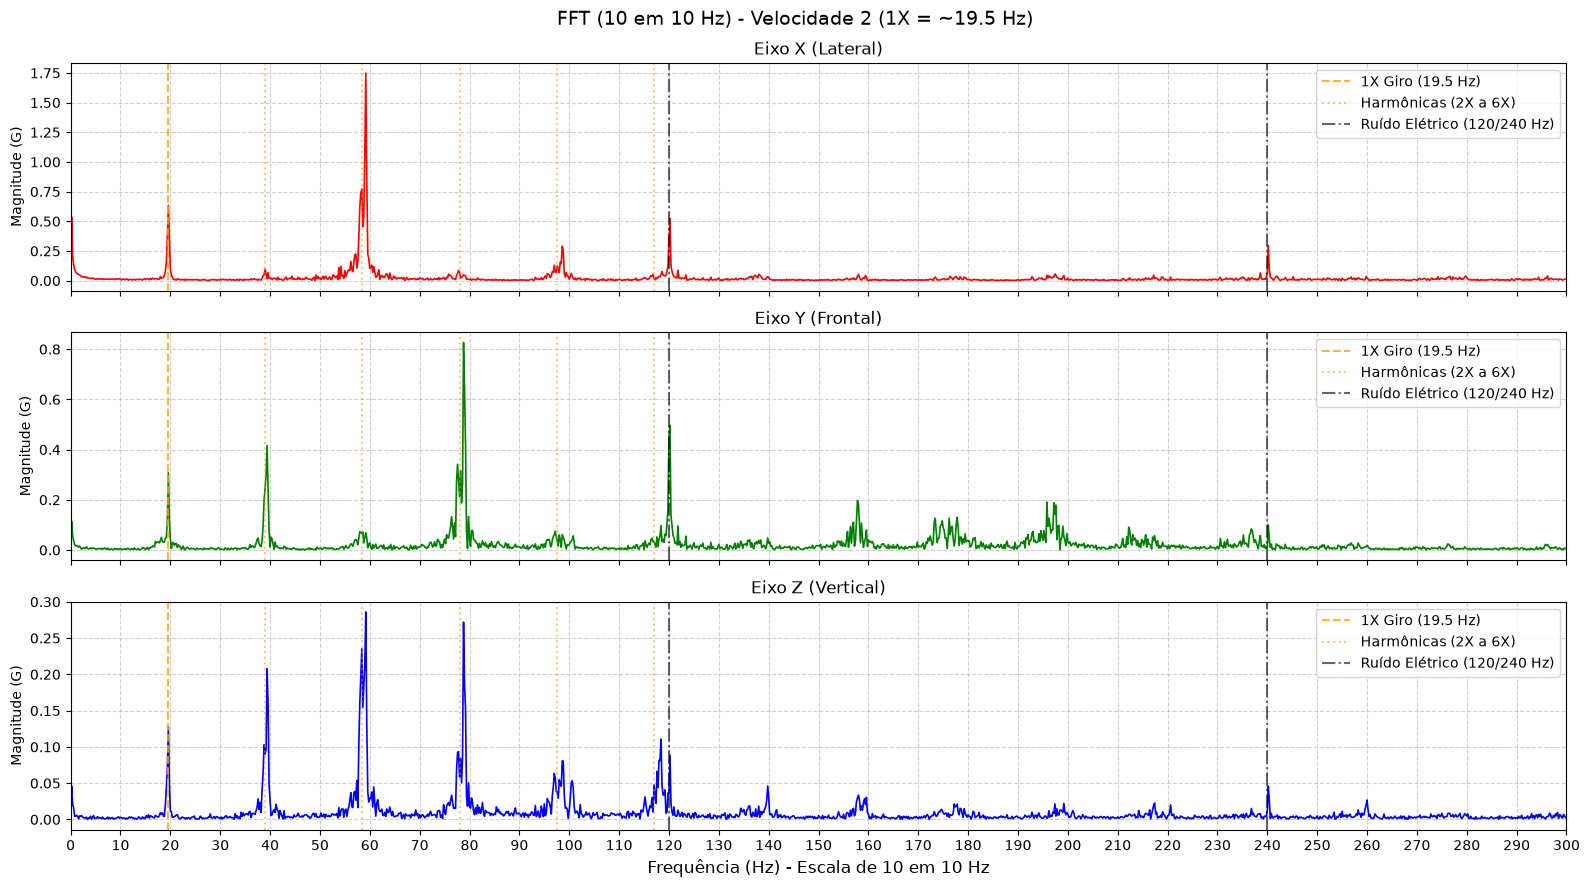

In [107]:
# =====================================================================
# 1. DEFININDO OS PARÂMETROS E A RÉGUA DE FREQUÊNCIAS
# =====================================================================
taxa_amostragem = 1000  # 1000 Hz
segundos = 5
N = segundos * taxa_amostragem  # 5000 amostras

# Régua horizontal de frequências (de 0 a 500 Hz, pulando de 0.2 em 0.2 Hz)
frequencias = np.fft.rfftfreq(N, d=1.0 / taxa_amostragem)

# =====================================================================
# 2. CRIANDO AS VARIÁVEIS DA FFT (Direto dos seus 3 DataFrames)
# =====================================================================
# --- VELOCIDADE 2 ---
recorte_v2 = df_vel2.iloc[:N]
fft_v2_x = np.abs(np.fft.rfft(recorte_v2['x'] - recorte_v2['x'].mean())) * (2.0 / N)
fft_v2_y = np.abs(np.fft.rfft(recorte_v2['y'] - recorte_v2['y'].mean())) * (2.0 / N)
fft_v2_z = np.abs(np.fft.rfft(recorte_v2['z'] - recorte_v2['z'].mean())) * (2.0 / N)


# =====================================================================
# 3. PLOTANDO COM A RÉGUA DE 10 EM 10 HZ
# =====================================================================
# Escolha aqui qual velocidade desenhar (v1, v2 ou v3):
sinais = [fft_v2_x, fft_v2_y, fft_v2_z]
freq_base_motor = 19.5  # Use 11.2 para Vel 1 | 19.5 para Vel 2 | 23.5 para Vel 3
titulo_vel = "Velocidade 2 (1X = ~19.5 Hz)"

fig, axs = plt.subplots(3, 1, figsize=(16, 9), sharex=True)
fig.suptitle(f"FFT (10 em 10 Hz) - {titulo_vel}", fontsize=14)

nomes = ["Eixo X (Lateral)", "Eixo Y (Frontal)", "Eixo Z (Vertical)"]
cores = ["red", "green", "blue"]

for i, ax in enumerate(axs):
    ax.plot(frequencias, sinais[i], color=cores[i], linewidth=1.2)
    ax.set_title(nomes[i], fontsize=12)
    ax.set_ylabel("Magnitude (G)")
    ax.set_xlim(0, 300)
    
    # Marcando o Giro Principal (1X) e Harmônicas (2X a 6X)
    ax.axvline(freq_base_motor, color='orange', linestyle='--', alpha=0.8, label=f'1X Giro ({freq_base_motor} Hz)')
    for mult in range(2, 7):
        ax.axvline(
            freq_base_motor * mult, color='darkorange', linestyle=':', alpha=0.5,
            label='Harmônicas (2X a 6X)' if mult == 2 else ""
        )
        
    # Marcando o Ruído Elétrico (120 Hz e 240 Hz)
    ax.axvline(120, color='black', linestyle='-.', alpha=0.6, label='Ruído Elétrico (120/240 Hz)')
    ax.axvline(240, color='black', linestyle='-.', alpha=0.6)
    
    # Eixo X numerado de 10 em 10 Hz
    ax.set_xticks(np.arange(0, 301, 10))
    
    ax.grid(which='major', linestyle='--', alpha=0.6)
    ax.legend(loc='upper right')

axs[2].set_xlabel("Frequência (Hz) - Escala de 10 em 10 Hz", fontsize=12)
plt.tight_layout()
plt.show()

## 2.4. Aplicando a FFT Crucial na Velocidade 3 (Alta)
Na **Velocidade 3**, o giro principal da hélice avança para **~23,5 Hz** (e seus múltiplos **~47 Hz, ~70,5 Hz e ~94 Hz**). Como o ventilador saiu da faixa de ressonância da Velocidade 2, as harmônicas mecânicas diminuem de altura, enquanto o ruído elétrico de **120 Hz** continua estático no mesmo lugar.

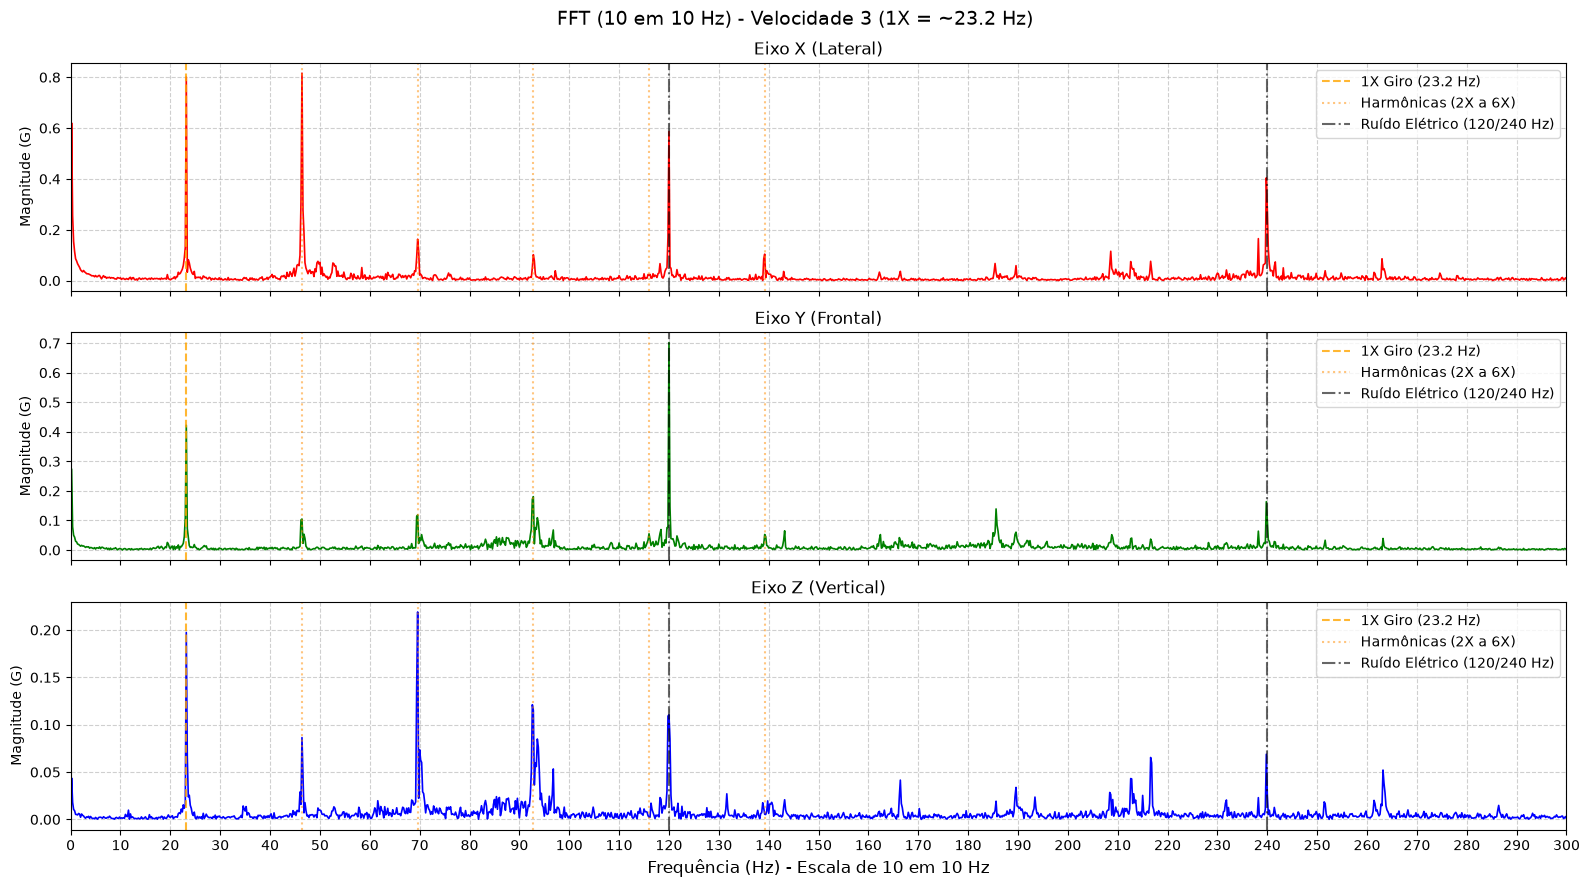

In [109]:
# =====================================================================
# 1. DEFININDO OS PARÂMETROS E A RÉGUA DE FREQUÊNCIAS
# =====================================================================
taxa_amostragem = 1000  # 1000 Hz
segundos = 5
N = segundos * taxa_amostragem  # 5000 amostras

# Régua horizontal de frequências (de 0 a 500 Hz, pulando de 0.2 em 0.2 Hz)
frequencias = np.fft.rfftfreq(N, d=1.0 / taxa_amostragem)

# =====================================================================
# 2. CRIANDO AS VARIÁVEIS DA FFT (Direto dos seus 3 DataFrames)
# =====================================================================
# --- VELOCIDADE 3 ---
recorte_v3 = df_vel3.iloc[:N]
fft_v3_x = np.abs(np.fft.rfft(recorte_v3['x'] - recorte_v3['x'].mean())) * (2.0 / N)
fft_v3_y = np.abs(np.fft.rfft(recorte_v3['y'] - recorte_v3['y'].mean())) * (2.0 / N)
fft_v3_z = np.abs(np.fft.rfft(recorte_v3['z'] - recorte_v3['z'].mean())) * (2.0 / N)


# =====================================================================
# 3. PLOTANDO COM A RÉGUA DE 10 EM 10 HZ
# =====================================================================
# Escolha aqui qual velocidade desenhar (v1, v2 ou v3):
sinais = [fft_v3_x, fft_v3_y, fft_v3_z]
freq_base_motor = 23.2  # Use 11.2 para Vel 1 | 19.5 para Vel 2 | 23.5 para Vel 3
titulo_vel = "Velocidade 3 (1X = ~23.2 Hz)"

fig, axs = plt.subplots(3, 1, figsize=(16, 9), sharex=True)
fig.suptitle(f"FFT (10 em 10 Hz) - {titulo_vel}", fontsize=14)

nomes = ["Eixo X (Lateral)", "Eixo Y (Frontal)", "Eixo Z (Vertical)"]
cores = ["red", "green", "blue"]

for i, ax in enumerate(axs):
    ax.plot(frequencias, sinais[i], color=cores[i], linewidth=1.2)
    ax.set_title(nomes[i], fontsize=12)
    ax.set_ylabel("Magnitude (G)")
    ax.set_xlim(0, 300)
    
    # Marcando o Giro Principal (1X) e Harmônicas (2X a 6X)
    ax.axvline(freq_base_motor, color='orange', linestyle='--', alpha=0.8, label=f'1X Giro ({freq_base_motor} Hz)')
    for mult in range(2, 7):
        ax.axvline(
            freq_base_motor * mult, color='darkorange', linestyle=':', alpha=0.5,
            label='Harmônicas (2X a 6X)' if mult == 2 else ""
        )
        
    # Marcando o Ruído Elétrico (120 Hz e 240 Hz)
    ax.axvline(120, color='black', linestyle='-.', alpha=0.6, label='Ruído Elétrico (120/240 Hz)')
    ax.axvline(240, color='black', linestyle='-.', alpha=0.6)
    
    # Eixo X numerado de 10 em 10 Hz
    ax.set_xticks(np.arange(0, 301, 10))
    
    ax.grid(which='major', linestyle='--', alpha=0.6)
    ax.legend(loc='upper right')

axs[2].set_xlabel("Frequência (Hz) - Escala de 10 em 10 Hz", fontsize=12)
plt.tight_layout()
plt.show()

# Passo 3: Tratamento da FFT e Análise Espectral Avançada

## 3.1. Aplicação da Janela de Hanning (Correção do Vazamento Espectral)
Quando recortamos 5 segundos de dados de forma abrupta, as ondas nas extremidades do recorte são cortadas ao meio, gerando ruído falso na base dos picos da FFT (*Spectral Leakage*). 

Aplicamos a **Janela de Hanning (`np.hanning`)** para atenuar suavemente as bordas do recorte de 5 segundos antes do cálculo da FFT, tornando os picos de frequência mais finos e nítidos.

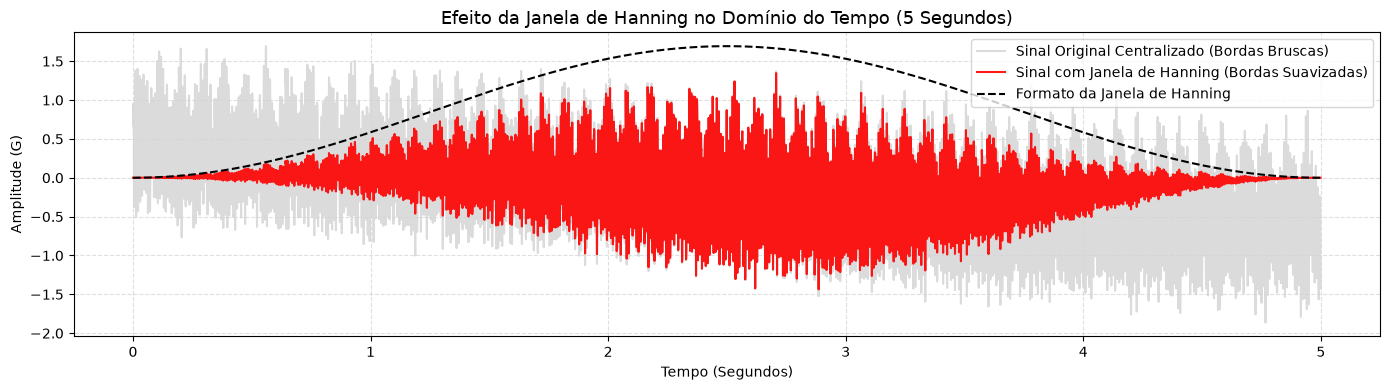

In [110]:
taxa_amostragem = 1000
segundos = 5
N = segundos * taxa_amostragem

# Criando a curva da Janela de Hanning para 5000 pontos
janela_hanning = np.hanning(N)

# Visualizando rapidamente o que a Janela de Hanning faz em 1 segundo do Eixo X (Vel 1)
sinal_bruto_zero = df_vel1['x'].iloc[:N] - df_vel1['x'].iloc[:N].mean()
sinal_com_hanning = sinal_bruto_zero * janela_hanning
tempo_5s = np.linspace(0, segundos, N, endpoint=False)

plt.figure(figsize=(14, 4))
plt.plot(tempo_5s, sinal_bruto_zero, color='lightgray', label='Sinal Original Centralizado (Bordas Bruscas)', alpha=0.8)
plt.plot(tempo_5s, sinal_com_hanning, color='red', label='Sinal com Janela de Hanning (Bordas Suavizadas)', alpha=0.9)
plt.plot(tempo_5s, janela_hanning * sinal_bruto_zero.max(), color='black', linestyle='--', label='Formato da Janela de Hanning')
plt.title("Efeito da Janela de Hanning no Domínio do Tempo (5 Segundos)", fontsize=13)
plt.xlabel("Tempo (Segundos)")
plt.ylabel("Amplitude (G)")
plt.legend(loc="upper right")
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

## 3.2. Comparação: FFT Crucial vs. FFT Tratada (Hanning + Filtro Passa-Alta > 5 Hz)

Aplicamos o tratamento completo preservando todas as frequências operacionais e elétricas do ventilador:
1. **Filtro Passa-Alta (`f > 5 Hz`):** Remove exclusivamente a deriva lenta (0 a 5 Hz) causada pela acomodação mecânica ou térmica do sensor.
2. **Janela de Hanning com Compensação de Energia (`* 4.0 / N`):** Afina a base de todas as frequências, eliminando o vazamento espectral ao redor do pico de 120 Hz e destacando as bandas laterais reais.

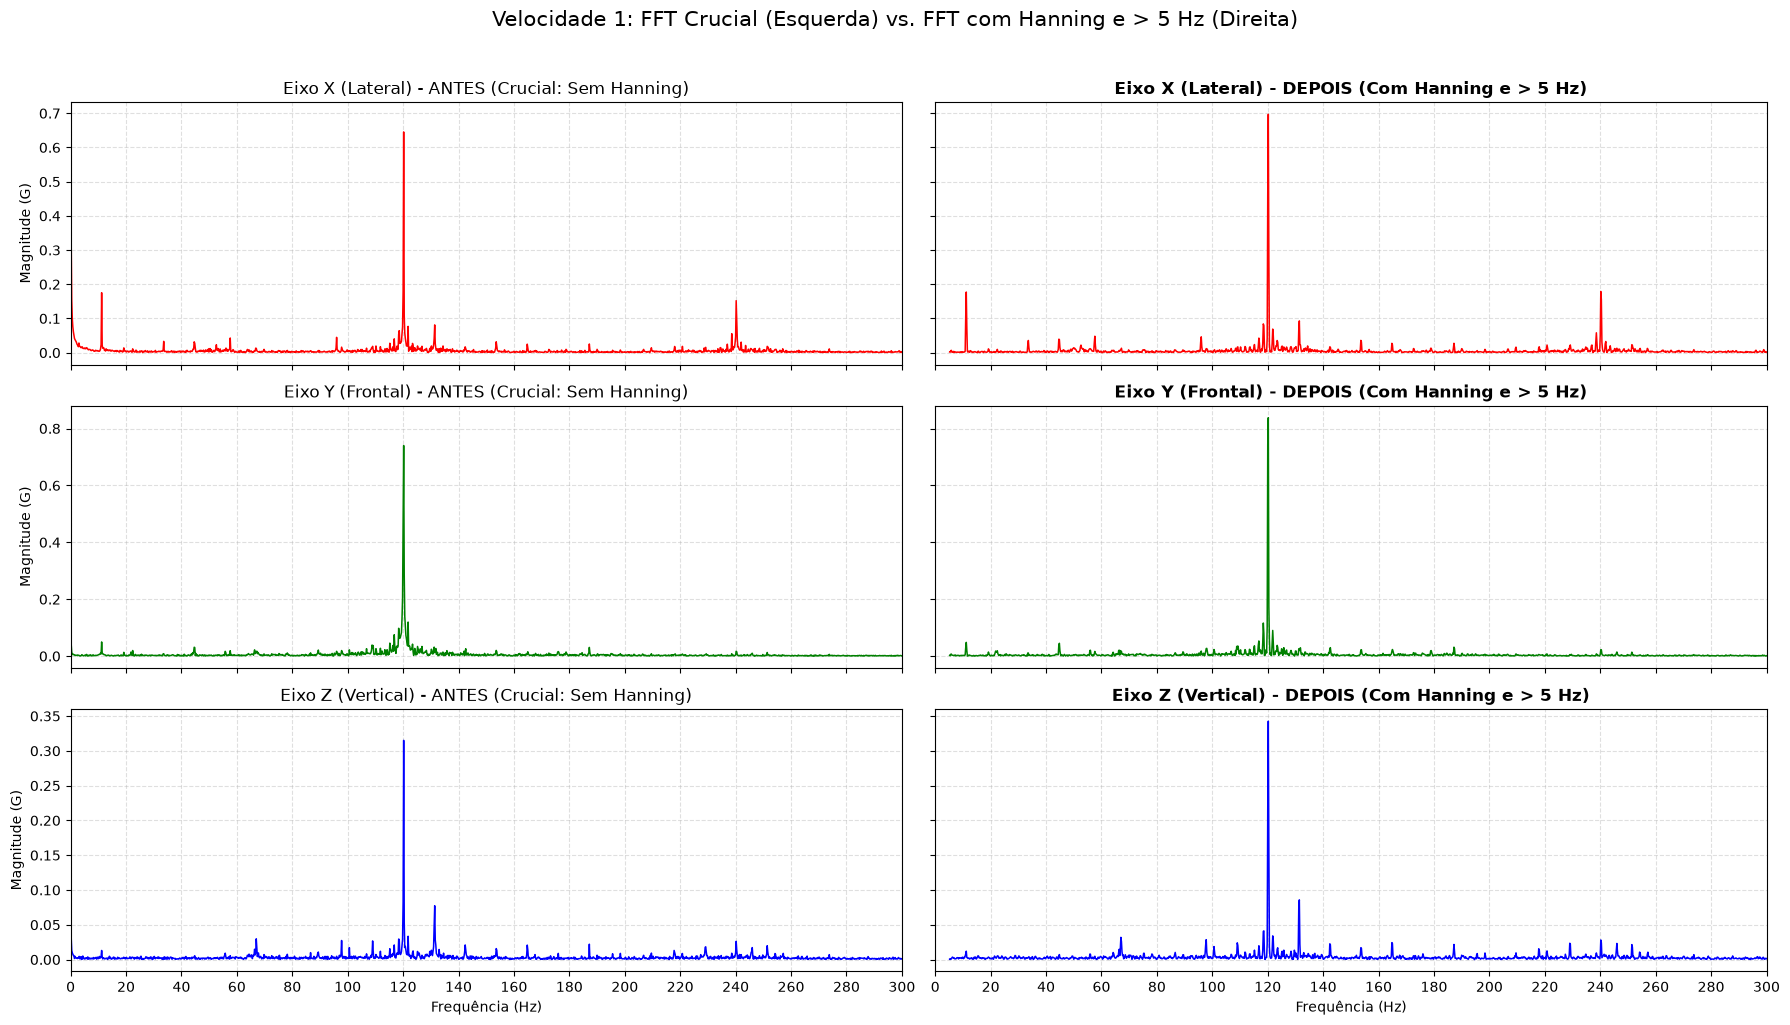

In [113]:
def calcular_fft_hanning(df_velocidade, segundos=5, taxa_amostragem=1000):
    """
    Calcula a FFT Tratada mantendo 100% das frequências reais do sistema:
    1. Centraliza no zero (remove gravidade estática de 0 Hz).
    2. Aplica Janela de Hanning (elimina vazamento espectral nas bases dos picos).
    3. Filtra f > 5 Hz (remove apenas a rampa lenta de deriva do sensor).
    """
    N = segundos * taxa_amostragem
    recorte = df_velocidade.iloc[:N]
    janela = np.hanning(N)
    
    frequencias = np.fft.rfftfreq(N, d=1.0 / taxa_amostragem)
    
    # Multiplicando pela janela de Hanning e compensando a perda de borda (* 4.0 / N)
    fft_x = np.abs(np.fft.rfft((recorte['x'] - recorte['x'].mean()) * janela)) * (4.0 / N)
    fft_y = np.abs(np.fft.rfft((recorte['y'] - recorte['y'].mean()) * janela)) * (4.0 / N)
    fft_z = np.abs(np.fft.rfft((recorte['z'] - recorte['z'].mean()) * janela)) * (4.0 / N)
    
    # Mantendo todas as frequências acima de 5 Hz (preserva giro, harmônicas e 120/240 Hz)
    mascara_5hz = frequencias > 5.0
    freqs_tratadas = frequencias[mascara_5hz]
    
    return freqs_tratadas, (fft_x[mascara_5hz], fft_y[mascara_5hz], fft_z[mascara_5hz])

# Calculando para a Velocidade 1
freqs_trat, fft_v1_trat = calcular_fft_hanning(df_vel1, segundos=5)

# Plotando o ANTES (FFT Crucial) vs DEPOIS (Com Hanning e > 5 Hz) na Velocidade 1
fig, axs = plt.subplots(3, 2, figsize=(18, 10), sharex=True, sharey='row')
fig.suptitle("Velocidade 1: FFT Crucial (Esquerda) vs. FFT com Hanning e > 5 Hz (Direita)", fontsize=15, y=1.02)

sinais_cruciais_v1 = [fft_v1_x, fft_v1_y, fft_v1_z]
nomes = ["Eixo X (Lateral)", "Eixo Y (Frontal)", "Eixo Z (Vertical)"]
cores = ["red", "green", "blue"]

for i in range(3):
    # Esquerda: FFT Crucial (Com rampa no 0 Hz e vazamento na base dos 120 Hz)
    axs[i, 0].plot(frequencias, sinais_cruciais_v1[i], color=cores[i], linewidth=1.1)
    axs[i, 0].set_title(f"{nomes[i]} - ANTES (Crucial: Sem Hanning)", fontsize=12)
    axs[i, 0].set_ylabel("Magnitude (G)")
    
    # Direita: FFT com Hanning e > 5 Hz (Picos finos e sem rampa inicial)
    axs[i, 1].plot(freqs_trat, fft_v1_trat[i], color=cores[i], linewidth=1.1)
    axs[i, 1].set_title(f"{nomes[i]} - DEPOIS (Com Hanning e > 5 Hz)", fontsize=12, fontweight='bold')
    
    for col in [0, 1]:
        axs[i, col].set_xlim(0, 300)
        axs[i, col].set_xticks(np.arange(0, 301, 20))
        axs[i, col].grid(True, linestyle='--', alpha=0.4)

axs[2, 0].set_xlabel("Frequência (Hz)")
axs[2, 1].set_xlabel("Frequência (Hz)")
plt.tight_layout()
plt.show()

## 3.3. Espectro Tratado das 3 Velocidades (Padrão Final com Hanning)
Com a aplicação da Janela de Hanning e a remoção da deriva abaixo de 5 Hz, consolidamos o espectro das três velocidades operacionais mantendo tanto a assinatura mecânica (rotação e harmônicas) quanto a assinatura eletromagnética (120 Hz e 240 Hz).

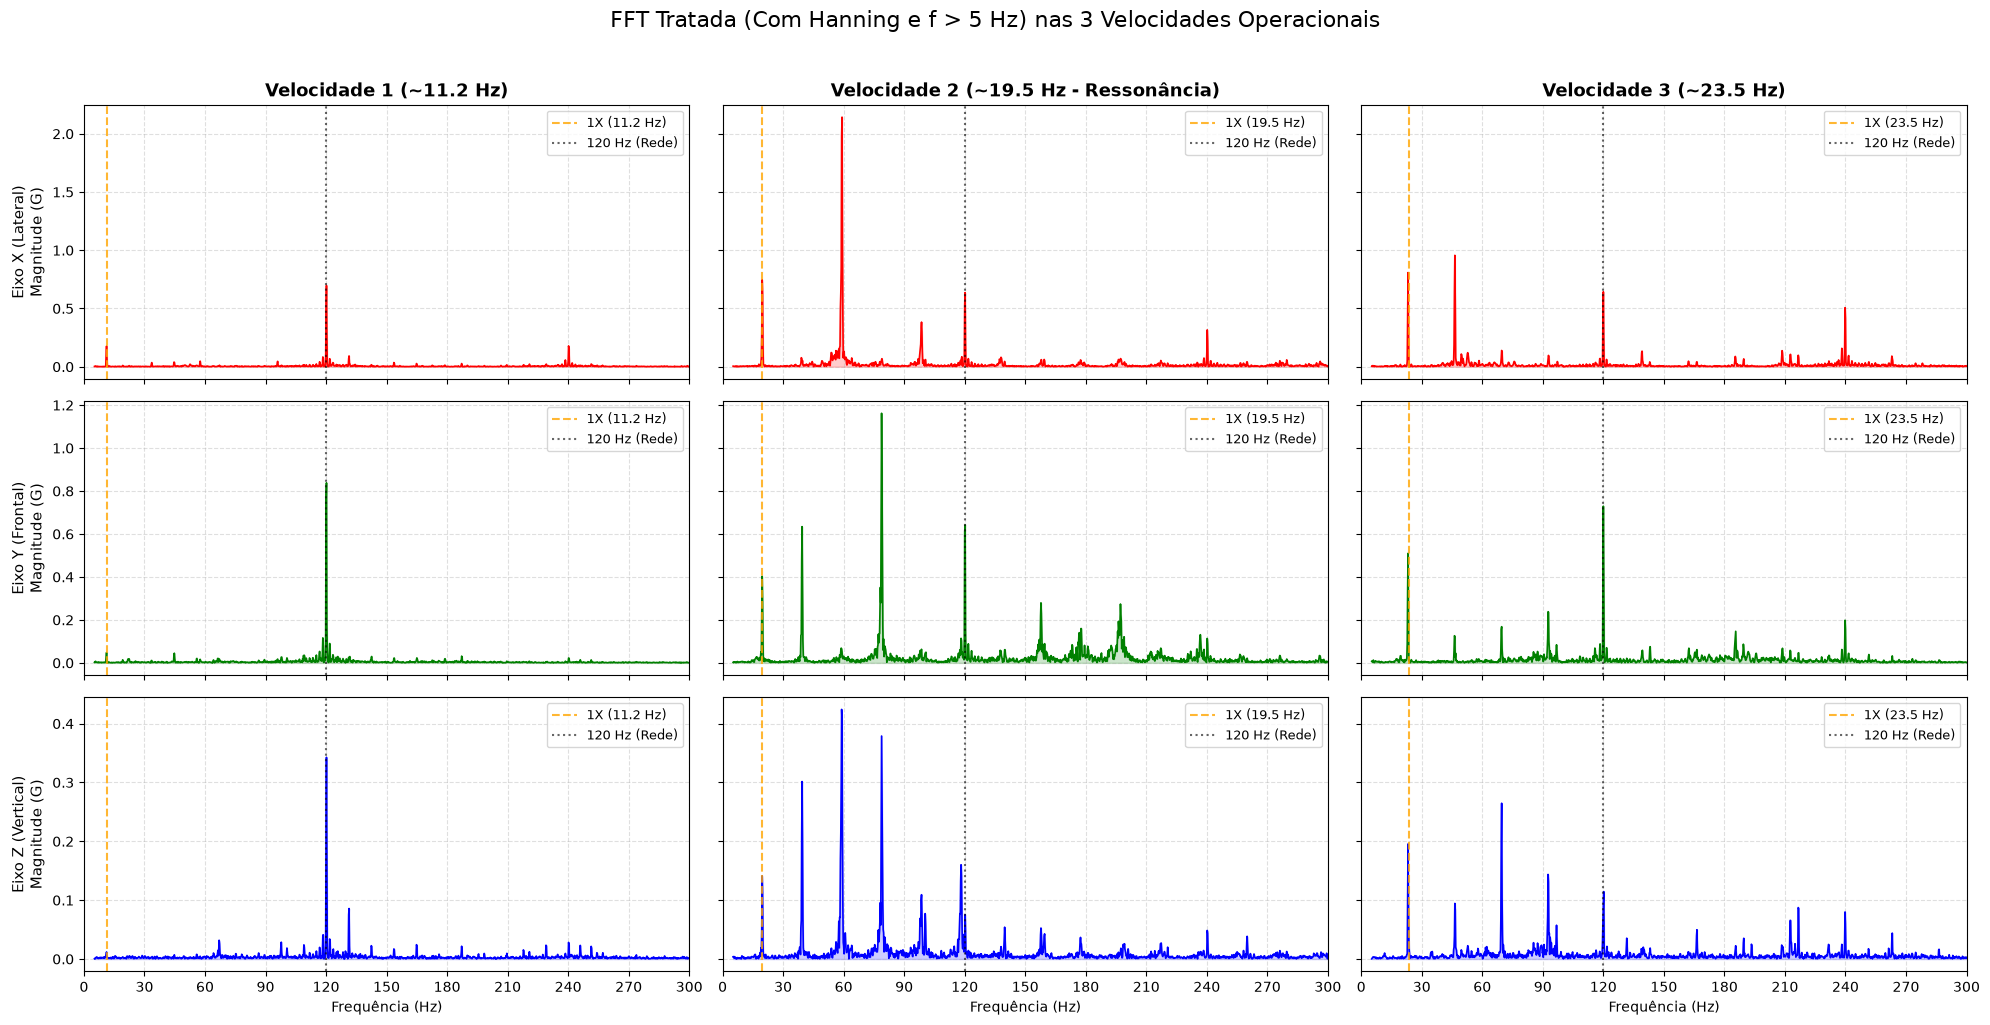

In [114]:
# Calculando a FFT com Hanning para as Velocidades 2 e 3
_, fft_v2_trat = calcular_fft_hanning(df_vel2, segundos=5)
_, fft_v3_trat = calcular_fft_hanning(df_vel3, segundos=5)

ffts_finais = [fft_v1_trat, fft_v2_trat, fft_v3_trat]
freqs_base = [11.2, 19.5, 23.5]
titulos_col = ["Velocidade 1 (~11.2 Hz)", "Velocidade 2 (~19.5 Hz - Ressonância)", "Velocidade 3 (~23.5 Hz)"]

fig, axs = plt.subplots(3, 3, figsize=(20, 10), sharex=True, sharey='row')
fig.suptitle("FFT Tratada (Com Hanning e f > 5 Hz) nas 3 Velocidades Operacionais", fontsize=16, y=1.02)

for linha_eixo in range(3):
    for col_vel in range(3):
        ax = axs[linha_eixo, col_vel]
        ax.plot(freqs_trat, ffts_finais[col_vel][linha_eixo], color=cores[linha_eixo], linewidth=1.2)
        ax.fill_between(freqs_trat, ffts_finais[col_vel][linha_eixo], color=cores[linha_eixo], alpha=0.2)
        
        # Marcando Giro 1X e Ruído Elétrico de 120 Hz
        f_motor = freqs_base[col_vel]
        ax.axvline(f_motor, color='orange', linestyle='--', alpha=0.8, label=f'1X ({f_motor} Hz)')
        ax.axvline(120, color='black', linestyle=':', alpha=0.6, label='120 Hz (Rede)')
        
        if linha_eixo == 0:
            ax.set_title(titulos_col[col_vel], fontsize=13, fontweight='bold')
        if col_vel == 0:
            ax.set_ylabel(f"{nomes[linha_eixo]}\nMagnitude (G)", fontsize=11)
        if linha_eixo == 2:
            ax.set_xlabel("Frequência (Hz)")
            
        ax.set_xlim(5, 300)
        ax.set_xticks(np.arange(0, 301, 30))
        ax.grid(True, linestyle='--', alpha=0.4)
        ax.legend(loc='upper right', fontsize=9)

plt.tight_layout()
plt.show()

## 3.4. O Espectrograma Completo (Evolução Temporal das Frequências com 120 Hz e 240 Hz)

Enquanto a FFT analisa uma janela estática de 5 segundos, o **Espectrograma (STFT - Short-Time Fourier Transform)** divide os 30 minutos de ensaio (1800 segundos) em centenas de janelas consecutivas de 2 segundos (aplicando a Janela de Hanning em cada uma) e exibe os picos vistos de cima (onde a cor representa a Magnitude em G).

Ao mantermos todo o espectro até **300 Hz** no **Eixo X**, comprovamos visualmente a diferença entre os dois fenômenos físicos do ventilador:
1. **Frequências Elétricas Fixas (120 Hz e 240 Hz):** Formam linhas horizontais contínuas do início ao fim do teste, pois a frequência da rede elétrica não depende da rotação da hélice.
2. **Frequências Mecânicas em Degraus (Rotação 1X e Harmônicas):** Deslocam-se verticalmente formando 3 patamares claros nos instantes de mudança de velocidade (~640s e ~1250s).

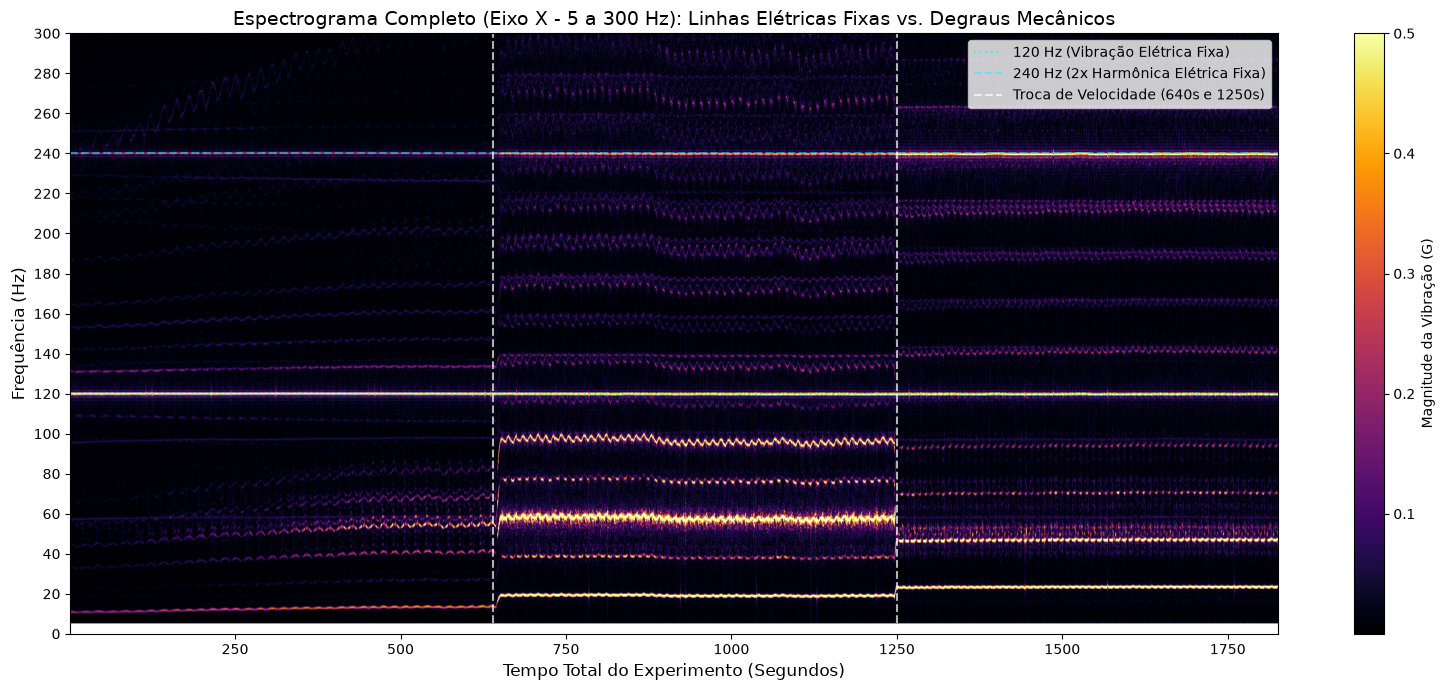

In [116]:
from scipy import signal
import numpy as np
import matplotlib.pyplot as plt

# 1. Selecionando a série inteira do Eixo X (os 30 minutos) e centralizando no zero
sinal_x_completo = df_1khz['x'].values - df_1khz['x'].mean()
taxa_amostragem = 1000

# 2. Calculando o Espectrograma (Janelas de 2 segundos = 2000 pontos com Hanning)
freqs_spec, tempos_spec, matriz_energia = signal.spectrogram(
    sinal_x_completo,
    fs=taxa_amostragem,
    window='hann',     # Aplica a mesma Janela de Hanning que usamos na Etapa 3.2
    nperseg=2000,      # Cada fatia tem 2 segundos
    noverlap=1000,     # Sobreposição de 1 segundo para suavizar a transição
    scaling='spectrum'
)

# Convertendo energia para Magnitude física em Força G
matriz_magnitude = np.sqrt(matriz_energia) * 2.0

# 3. Filtrando apenas f > 5 Hz até 300 Hz (Mantendo 120 Hz e 240 Hz!)
mascara_freq = (freqs_spec > 5.0) & (freqs_spec <= 300.0)
freqs_plot = freqs_spec[mascara_freq]
matriz_plot = matriz_magnitude[mascara_freq, :]

# 4. Plotando o Espectrograma comentando as regiões
plt.figure(figsize=(16, 7))
plt.pcolormesh(tempos_spec, freqs_plot, matriz_plot, shading='gouraud', cmap='inferno', vmax=0.5)

# Linhas de referência para guiar o olho nas frequências elétricas fixas
plt.axhline(120, color='cyan', linestyle=':', alpha=0.6, label='120 Hz (Vibração Elétrica Fixa)')
plt.axhline(240, color='cyan', linestyle='--', alpha=0.5, label='240 Hz (2x Harmônica Elétrica Fixa)')

# Linhas verticais mostrando onde a velocidade foi trocada (visto no Passo 1)
plt.axvline(640, color='white', linestyle='--', alpha=0.7, label='Troca de Velocidade (640s e 1250s)')
plt.axvline(1250, color='white', linestyle='--', alpha=0.7)

plt.title('Espectrograma Completo (Eixo X - 5 a 300 Hz): Linhas Elétricas Fixas vs. Degraus Mecânicos', fontsize=14)
plt.ylabel('Frequência (Hz)', fontsize=12)
plt.xlabel('Tempo Total do Experimento (Segundos)', fontsize=12)
plt.yticks(np.arange(0, 301, 20))
plt.colorbar(label='Magnitude da Vibração (G)')
plt.legend(loc='upper right', fontsize=10)
plt.tight_layout()
plt.show()